# EDA del panel

Análisis exploratorio (EDA) de `data/panel.csv`, que sale de `04_build_panel.ipynb`.

## Carga del panel y selección de empresas

In [56]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [57]:
# Montar Google Drive si estamos en Google Colab

if "google.colab" in sys.modules:
    from google.colab import drive  # type: ignore

    drive.mount("/content/drive")

    CANDIDATOS = [
        Path("/content/drive/MyDrive/Colab Notebooks/Diplodatos MAI Grupo 6"),
        Path("/content/drive/MyDrive/Diplodatos MAI Grupo 6"),
    ]
    WORKING_DIR = next((p for p in CANDIDATOS if p.exists()), None)
    if WORKING_DIR is None:
        raise FileNotFoundError(
            "No encuentro la carpeta del grupo. ¿Agregaste el acceso directo "
            "en 'Mi unidad' desde 'Compartido conmigo'?"
        )
    sys.path.append(str(WORKING_DIR))  # to import `shared`
else:
    WORKING_DIR = Path.cwd()

from shared.concepts import CONCEPTS
from shared.constants import COVID, N_TRIMESTRES, TRIMESTRES

In [75]:
panel = pd.read_csv(f"{WORKING_DIR}/data/panel.csv", dtype={"cik": str})
panel.head()

,cik,nombre,sector,trimestre,fecha_presentacion,ingresos_netos,resultado_operativo,resultado_neto,activos_totales,activos_corrientes,...,caja,roe,roa,endeudamiento,liquidez_corriente,fco_ingresos,margen_bruto,margen_operativo,margen_neto,fecha_quiebra
0,1000229,CORE LABORATORIES N V,energia,2018Q1,20200210,170018000.0,32316000.0,23527000.0,597140000.0,220185000.0,...,13244000.0,0.159356,0.039399,NaN,2.110527,0.135827,NaN,0.190074,0.138379,NaN
1,1000229,CORE LABORATORIES N V,energia,2018Q2,20200210,175475000.0,33449000.0,24752000.0,604744000.0,225662000.0,...,13021000.0,0.160954,0.040930,NaN,2.243362,0.153811,NaN,0.190620,0.141057,NaN
2,1000229,CORE LABORATORIES N V,energia,2018Q3,20200210,182146000.0,34879000.0,22412000.0,666597000.0,239125000.0,...,14100000.0,0.142354,0.033622,NaN,2.310186,0.130900,NaN,0.191489,0.123044,NaN
3,1000229,CORE LABORATORIES N V,energia,2018Q4,20210208,173207000.0,17978000.0,8835000.0,648827000.0,230977000.0,...,13116000.0,0.056360,0.013617,NaN,2.252401,0.218819,NaN,0.103795,0.051008,NaN
4,1000229,CORE LABORATORIES N V,energia,2019Q1,20210208,169194000.0,16414000.0,40510000.0,791760000.0,236423000.0,...,13206000.0,0.221167,0.051164,NaN,1.838223,0.148681,NaN,0.097013,0.239429,NaN


### Empresas que salen sin quiebra

El panel no es balanceado: una empresa puede dejar de tener filas antes de 2024Q4. Si tiene `fecha_quiebra`, la cortó la quiebra (`docs/decisions.md`, sección 13). Si no, salió por otra razón que hoy no está documentada: una compra, un cambio de SIC fuera del sector, el paso a formularios de empresa extranjera (20-F) o dejó de presentar.

La celda clasifica cada empresa en uno de cuatro tipos:

- `quiebra`: tiene `fecha_quiebra`.
- `completa`: sin quiebra y con fila en los 28 trimestres (2018Q1–2024Q4).
- `huecos`: sin quiebra, llega a 2024Q4 pero le falta algún trimestre en el medio.
- `sale sin quiebra`: sin quiebra y su última fila es anterior a 2024Q4.

`trimestre` es texto `AAAAQN`, así que `max` en orden de texto es el último trimestre.

In [78]:
empresas = panel.groupby("cik").agg(
    sector=("sector", "first"),
    filas=("trimestre", "size"),
    ultimo=("trimestre", "max"),
    fecha_quiebra=("fecha_quiebra", "first"),
)

empresas["tipo"] = np.select(
    [
        empresas["fecha_quiebra"].notna(),
        empresas["filas"] == N_TRIMESTRES,
        empresas["ultimo"] == str(TRIMESTRES[-1]),
    ],
    ["quiebra", "completa", "huecos"],
    default="sin quiebra",
)

pd.crosstab(
    empresas["sector"],
    empresas["tipo"],
    margins=True,
    margins_name="total",
).rename(columns={"huecos": "faltantes"})

tipo,completa,faltantes,quiebra,sin quiebra,total
sector,,,,,
energia,83,4,46,112,245
salud,44,1,8,33,86
total,127,5,54,145,331


### Panel solo con quiebras y empresas completas

Se sacan las empresas que salen sin quiebra (sin causa documentada) y las que tienen huecos. Quedan las que quiebran y las que tienen fila en todos los trimestres. Desde acá el EDA usa `panel_qc`: una empresa que sale sin quiebra no aporta a ninguna de las preguntas del rumbo (`docs/decisions.md`, sección 14). `panel` no cambia.

In [81]:
panel_qc = panel[
    panel["cik"].isin(empresas.index[empresas["tipo"].isin(["quiebra", "completa"])])
]
panel_qc.groupby("sector").agg(empresas=("cik", "nunique"), filas=("cik", "size"))
# panel_qc.shape

,empresas,filas
sector,,
energia,129,2707
salud,52,1310


### Definiciones para los gráficos

La celda define lo que usan los gráficos: la función que sombrea el período COVID (`COVID`, en `shared/constants.py`), los colores, los nombres de los sectores y las empresas por sector (`n_empresas`).

In [61]:
COLORES = {"quiebra": "#eb6834"}
NOMBRES = {"energia": "Energía", "salud": "Salud"}

# empresas de panel_qc por sector (completas + quiebras)
n_empresas = (
    empresas[empresas["tipo"].isin(["quiebra", "completa"])].groupby("sector").size()
)


def sombrear_covid(ax, trimestres):
    """Sombrea COVID en un gráfico de barras con una barra por trimestre (en el orden de `trimestres`)."""
    x = ax.get_xticks()
    t = [str(q) for q in trimestres]
    ax.axvspan(
        x[t.index(COVID[0])] - 0.5,
        x[t.index(COVID[1])] + 0.5,
        color="#6b6b6b",
        alpha=0.25,
        linewidth=0,
        zorder=0,
        label="COVID",
    )


## Quiebras

Análisis de las empresas de `panel_qc` que quiebran (`quebradas`).

In [62]:
quebradas = empresas[empresas["tipo"] == "quiebra"]

### Quiebras por trimestre

Cantidad de quiebras por trimestre de `fecha_quiebra`. El título da el total de empresas del sector en `panel_qc` (completas y quiebras), y los dos paneles comparten el eje vertical.

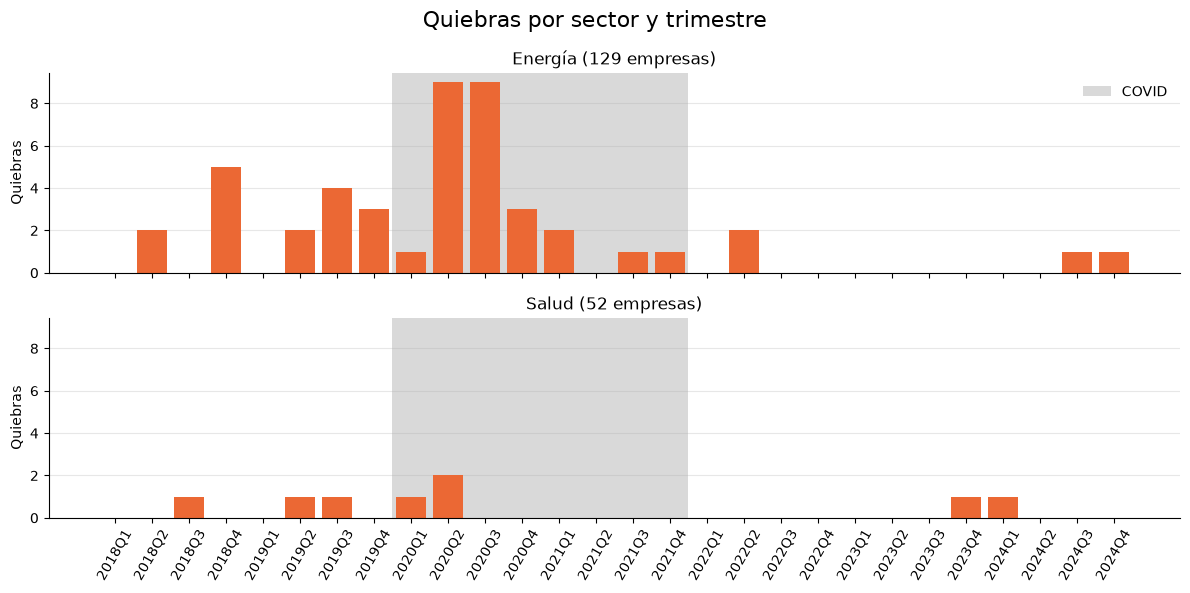

In [63]:
quiebras = pd.crosstab(
    pd.to_datetime(quebradas["fecha_quiebra"]).dt.to_period("Q"),
    quebradas["sector"],
).reindex(TRIMESTRES, fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)

for ax, sector in zip(axes, ["energia", "salud"]):
    ax.spines[["top", "right"]].set_visible(False)
    ax.bar(quiebras.index.astype(str), quiebras[sector], color=COLORES["quiebra"])
    sombrear_covid(ax, quiebras.index)
    ax.set_title(
        f"{NOMBRES[sector]} ({n_empresas[sector]} empresas)",
    )
    ax.set_ylabel("Quiebras")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)


axes[0].legend(frameon=False)
axes[-1].tick_params(axis="x", rotation=60)
fig.suptitle("Quiebras por sector y trimestre", fontsize=16)
fig.tight_layout()

### Trimestres entre la última fila y la quiebra

Para cada empresa de `panel_qc` que quiebra: trimestre de `fecha_quiebra` menos trimestre de su última fila. Desde el trimestre de la quiebra no hay filas (`docs/decisions.md`, sección 13), así que el mínimo es 1: la última fila es el trimestre anterior a la quiebra. Un valor mayor indica que la empresa se quedó sin filas antes de quebrar.

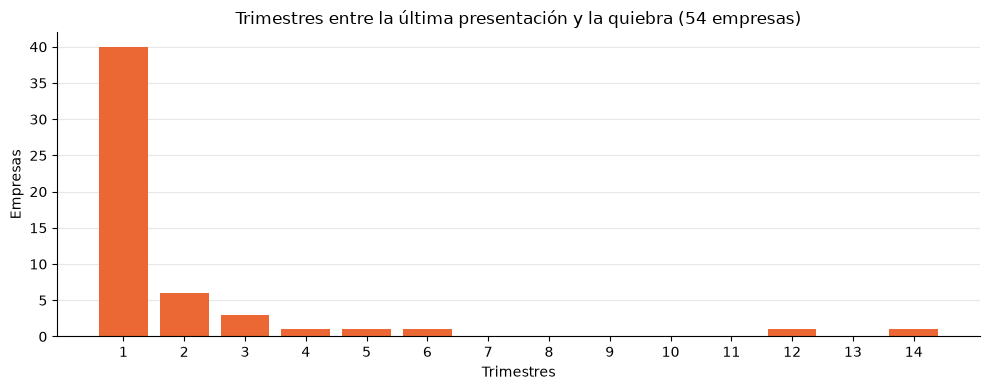

In [64]:
ultimas = (
    panel_qc[panel_qc["fecha_quiebra"].notna()]
    .groupby("cik")
    .agg(ultima_fila=("trimestre", "max"), fecha_quiebra=("fecha_quiebra", "first"))
)
# Period -> int counts quarters since 1970Q1, so the difference is in quarters
hasta_quiebra = pd.to_datetime(ultimas["fecha_quiebra"]).dt.to_period("Q").astype(
    int
) - pd.PeriodIndex(ultimas["ultima_fila"], freq="Q").astype(int)
por_distancia = hasta_quiebra.value_counts().reindex(
    range(1, hasta_quiebra.max() + 1), fill_value=0
)

fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.bar(
    por_distancia.index.astype(str), por_distancia, color=COLORES["quiebra"]
)
ax.set_title(
    f"Trimestres entre la última presentación y la quiebra ({len(ultimas)} empresas)"
)
ax.set_xlabel("Trimestres")
ax.set_ylabel("Empresas")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()

Lo mismo, por sector. Los dos paneles comparten los ejes.

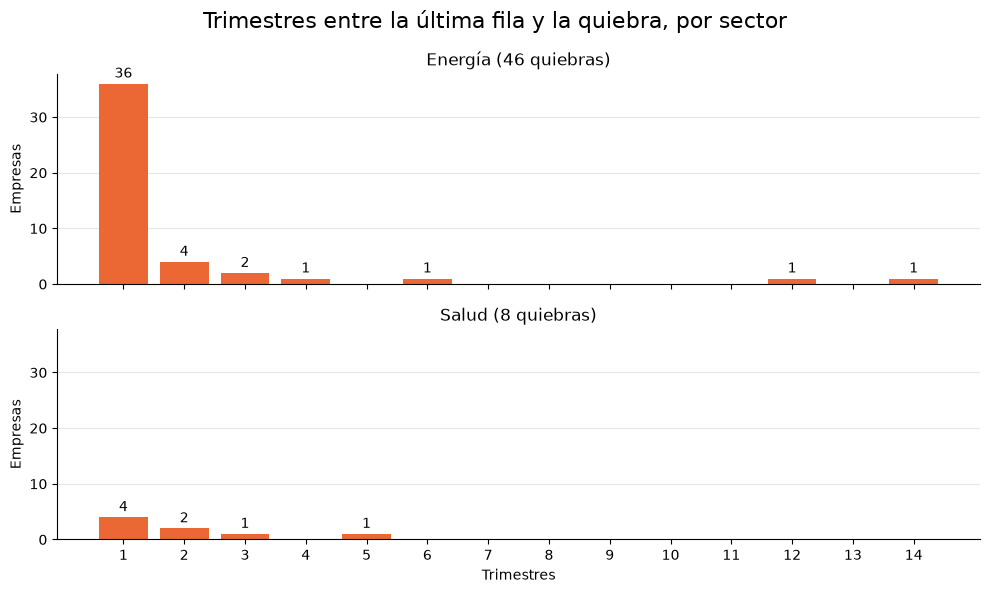

In [65]:
por_sector = pd.crosstab(
    hasta_quiebra, empresas.loc[hasta_quiebra.index, "sector"]
).reindex(range(1, hasta_quiebra.max() + 1), fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
for ax, sector in zip(axes, ["energia", "salud"]):
    barras = ax.bar(
        por_sector.index.astype(str), por_sector[sector], color=COLORES["quiebra"]
    )
    ax.bar_label(
        barras, labels=[str(n) if n else "" for n in por_sector[sector]], padding=2
    )
    ax.set_title(f"{NOMBRES[sector]} ({por_sector[sector].sum()} quiebras)")
    ax.set_ylabel("Empresas")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Trimestres")
fig.suptitle("Trimestres entre la última fila y la quiebra, por sector", fontsize=16)
fig.tight_layout()

## Datos faltantes

El panel tiene cuatro dimensiones: sector × empresa × trimestre × concepto. No se pueden mirar juntas, así que se arma una tabla larga (`largo`) con una fila por empresa, trimestre y concepto, y una columna `falta` (el valor es NaN). Cada vista agrupa por algunas dimensiones y promedia las demás:

| Vista | Se ve | Se promedia |
|---|---|---|
| 1 | concepto × sector | empresas y trimestres |
| 2 | concepto × trimestre | empresas |
| 3 | empresa × concepto | trimestres |

Solo cuentan las filas que existen. Que una empresa no tenga filas desde su quiebra no es un faltante: es la regla del panel (`docs/decisions.md`, sección 13).

Por ahora solo los 11 conceptos. Los ratios heredan los faltantes de sus conceptos y se analizan después.

In [66]:
CONCEPTOS = [
    c for c in CONCEPTS if c != "costo_ventas"
]  # costo_ventas is not in the panel
AZUL = "#2a78d6"
ETIQUETAS = {c: c.replace("_", " ").capitalize() for c in CONCEPTOS}  # for the axes

largo = panel_qc.melt(
    id_vars=["cik", "sector", "trimestre"], value_vars=CONCEPTOS, var_name="concepto"
)
largo["falta"] = largo["value"].isna()

# share of each company's quarters without the concept
por_empresa = largo.groupby(["sector", "cik", "concepto"])["falta"].mean()


### Vista 1: faltantes por concepto y sector

Porcentaje de celdas (empresa × trimestre) sin dato. Ordenado por energía.

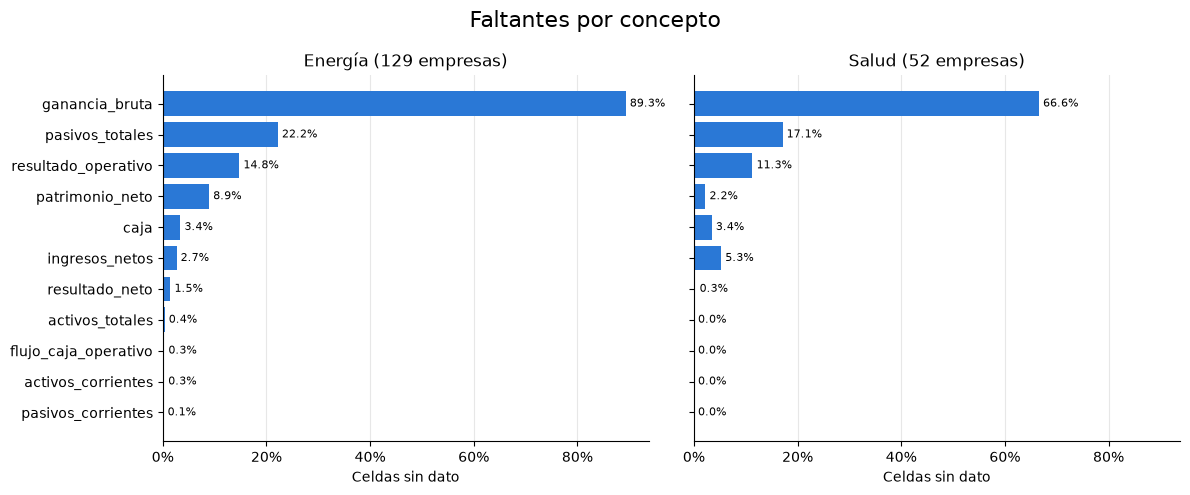

In [67]:
from matplotlib.ticker import PercentFormatter

vista1 = (
    largo.groupby(["concepto", "sector"])["falta"]
    .mean()
    .unstack()
    .sort_values("energia")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, sharex=True)
for ax, sector in zip(axes, ["energia", "salud"]):
    barras = ax.barh(vista1.index, vista1[sector], color=AZUL)
    ax.bar_label(
        barras, labels=[f"{v:.1%}" for v in vista1[sector]], padding=3, fontsize=8
    )
    ax.set_title(f"{NOMBRES[sector]} ({n_empresas[sector]} empresas)")
    ax.set_xlabel("Celdas sin dato")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
fig.suptitle("Faltantes por concepto", fontsize=16)
fig.tight_layout()
# vista1

### Vista 2: faltantes por concepto y trimestre

Un panel por concepto y una línea por sector. Si el faltante de un concepto cambia en el tiempo, suele ser un cambio de tag (por ejemplo, empresas que empiezan a reportar `Liabilities`).

Cada panel tiene su propia escala vertical: con una escala común, la ganancia bruta (cerca del 90%) aplasta a todos los demás conceptos.

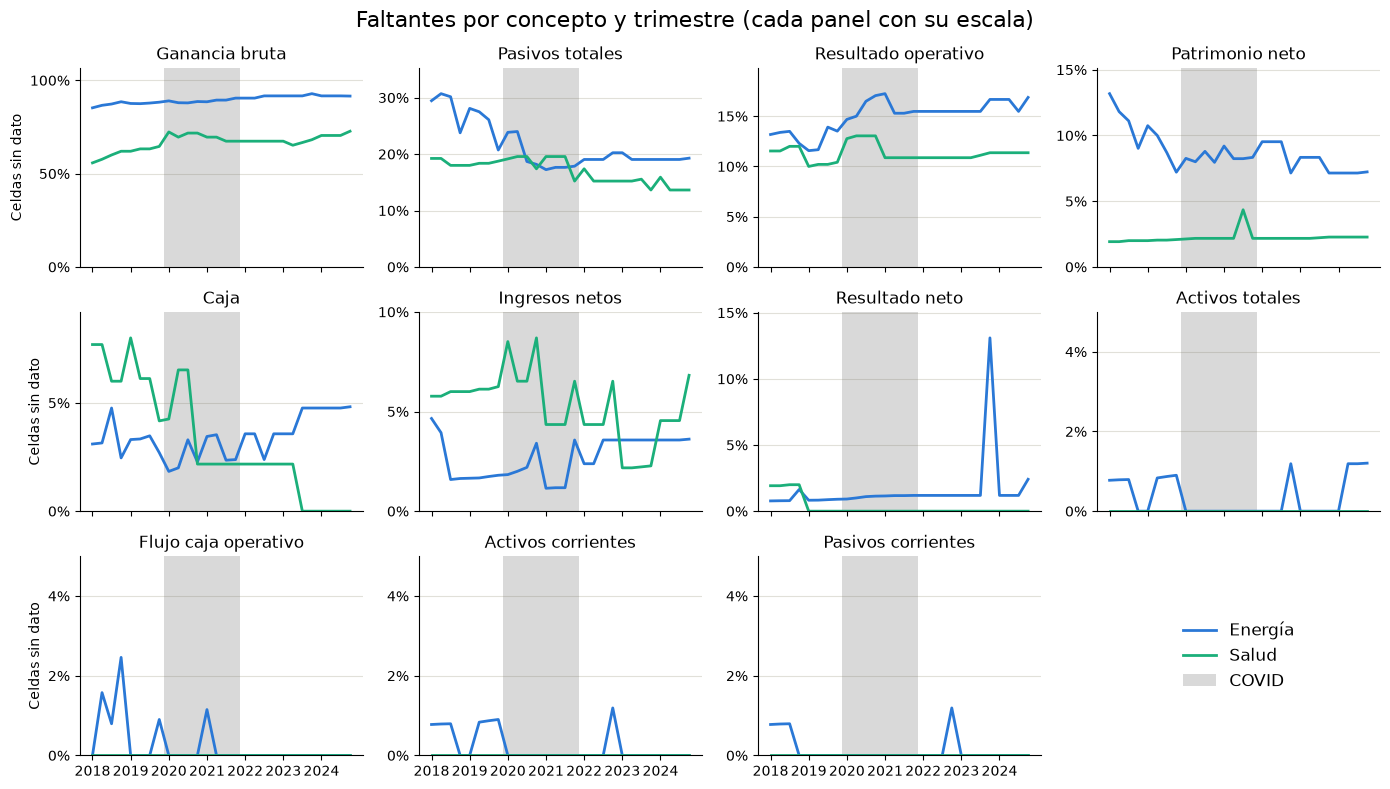

In [68]:
from matplotlib.ticker import MaxNLocator

vista2 = largo.groupby(["sector", "concepto", "trimestre"])["falta"].mean().unstack()
SECTORES = {"energia": AZUL, "salud": "#1baf7a"}
orden = vista1.index[::-1]  # the most missing first, as in vista 1
inicio_fin_covid = [
    list(vista2.columns).index(q) + d for q, d in zip(COVID, (-0.5, 0.5))
]

fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
for ax, concepto in zip(axes.flat, orden):
    for sector, color in SECTORES.items():
        ax.plot(
            vista2.columns,
            vista2.loc[(sector, concepto)],
            color=color,
            linewidth=2,
            label=NOMBRES[sector],
        )
    ax.axvspan(
        *inicio_fin_covid, color="#6b6b6b", alpha=0.25, linewidth=0, label="COVID"
    )
    ax.set_title(ETIQUETAS[concepto])
    ax.set_ylim(0, max(0.05, vista2.xs(concepto, level="concepto").max().max() * 1.15))
    ax.yaxis.set_major_locator(MaxNLocator(4, steps=[1, 2, 5, 10]))  # clean ticks
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xticks(range(0, N_TRIMESTRES, 4), [str(t.year) for t in TRIMESTRES[::4]])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9")
    ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel("Celdas sin dato")
axes.flat[-1].axis("off")
axes.flat[-1].legend(
    *axes.flat[0].get_legend_handles_labels(), loc="center", frameon=False, fontsize=12
)
fig.suptitle(
    "Faltantes por concepto y trimestre (cada panel con su escala)", fontsize=16
)
fig.tight_layout()

### Vista 3: ¿falta siempre o a veces?

Para cada empresa y concepto, el porcentaje de sus trimestres sin dato:

- `siempre está`: 0%.
- `a veces falta`: entre 0% y 100%. Son trimestres sueltos; es el único caso donde tiene sentido completar con el valor anterior.
- `nunca está`: 100%. La empresa no reporta ese concepto con ningún tag (faltante estructural).

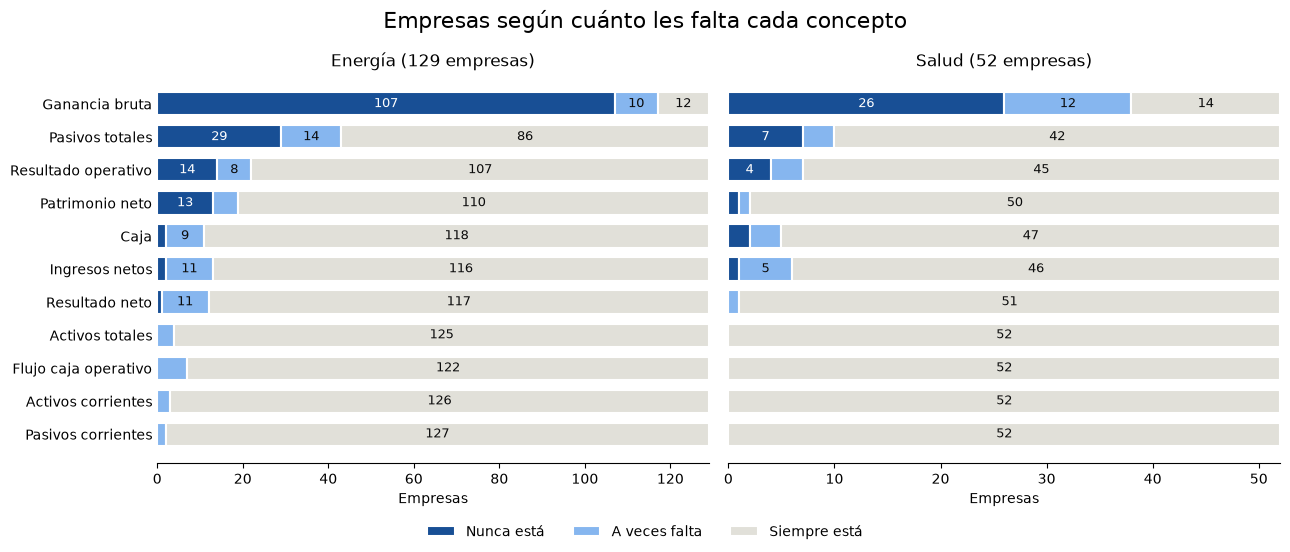

In [69]:
# order: from the problem to the normal case, so the bars start with "nunca está"
ESTADOS = {
    "nunca está": ("#184f95", "white"),
    "a veces falta": ("#86b6ef", "#0b0b0b"),
    "siempre está": ("#e1e0d9", "#0b0b0b"),
}

estado = pd.cut(
    por_empresa,
    [-0.01, 0, 0.999, 1],
    labels=["siempre está", "a veces falta", "nunca está"],
)
vista3 = estado.groupby(["sector", "concepto"], observed=False).value_counts().unstack()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, sector in zip(axes, ["energia", "salud"]):
    datos = vista3.loc[sector].reindex(vista1.index)
    izquierda = 0
    for nombre, (color, tinta) in ESTADOS.items():
        barras = ax.barh(
            [ETIQUETAS[c] for c in datos.index],
            datos[nombre],
            left=izquierda,
            height=0.7,
            color=color,
            label=nombre.capitalize(),
            edgecolor="white",
            linewidth=1.5,
        )
        # the count goes inside the segment only if it fits (>= 6% of the companies)
        ax.bar_label(
            barras,
            labels=[
                str(n) if n >= 0.06 * n_empresas[sector] else "" for n in datos[nombre]
            ],
            label_type="center",
            color=tinta,
            fontsize=9,
        )
        izquierda = izquierda + datos[nombre]
    ax.set_xlim(0, n_empresas[sector])
    ax.set_title(f"{NOMBRES[sector]} ({n_empresas[sector]} empresas)")
    ax.set_xlabel("Empresas")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.legend(
    *axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False
)
fig.suptitle("Empresas según cuánto les falta cada concepto", fontsize=16)
fig.tight_layout(rect=(0, 0.05, 1, 1))  # leaves room for the legend below
# vista3.unstack(0)

## Ratios: valores anómalos

Los 8 ratios del panel en `panel_qc`, en fracción (`docs/decisions.md`, sección 12). Buscamos valores anómalos, proponemos un umbral a partir de los datos y vemos a qué se deben.

In [70]:
# ratio -> column it divides by (as in 04_build_panel)
DENOMINADOR = {
    "roe": "patrimonio_neto",
    "roa": "activos_totales",
    "endeudamiento": "activos_totales",
    "liquidez_corriente": "pasivos_corrientes",
    "fco_ingresos": "ingresos_netos",
    "margen_bruto": "ingresos_netos",
    "margen_operativo": "ingresos_netos",
    "margen_neto": "ingresos_netos",
}
RATIOS = list(DENOMINADOR)
ETIQUETAS |= {
    "roe": "ROE",
    "roa": "ROA",
    "endeudamiento": "Endeudamiento",
    "liquidez_corriente": "Liquidez corriente",
    "fco_ingresos": "FCO / ingresos",
    "margen_bruto": "Margen bruto",
    "margen_operativo": "Margen operativo",
    "margen_neto": "Margen neto",
}

percentiles = (
    panel_qc.groupby("sector")[RATIOS]
    .quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 1])
    .T.rename(
        columns={
            0: "mín",
            0.01: "p1",
            0.25: "p25",
            0.5: "mediana",
            0.75: "p75",
            0.99: "p99",
            1: "máx",
        },
        level=1,
    )
)
percentiles.round(2)

sector              energia                                            \
                        mín     p1   p25 mediana   p75    p99     máx   
roe                  -35.75  -3.06 -0.03    0.01  0.06   2.26  180.29   
roa                  -93.81  -0.88 -0.02    0.00  0.02   0.17    9.01   
endeudamiento          0.01   0.02  0.20    0.39  0.60  11.51  889.96   
liquidez_corriente     0.00   0.02  0.73    1.38  2.79  54.41  125.71   
fco_ingresos       -1431.29  -5.45  0.08    0.32  0.60   1.77   23.02   
margen_bruto         -16.25  -3.51  0.04    0.14  0.24   1.00    1.00   
margen_operativo    -553.60 -13.21 -0.18    0.07  0.32   1.03   17.02   
margen_neto        -3143.48 -18.04 -0.24    0.03  0.25   2.05  126.25   

sector                salud                                              
                        mín      p1   p25 mediana   p75    p99      máx  
roe                  -71.89   -3.02 -0.08    0.02  0.05   1.62    19.50  
roa                 -213.05   -4.46 -0.06   -0.00  0.01   0.20   382.50  
endeudamiento          0.00    0.03  0.34    0.56  0.86  33.98  3143.39  
liquidez_corriente     0.00    0.01  1.09    1.52  3.00  29.34   359.40  
fco_ingresos       -1018.50  -96.84 -0.11    0.06  0.15   0.76   140.17  
margen_bruto          -4.74   -2.28  0.23    0.34  0.48   0.97     5.72  
margen_operativo   -1677.74 -364.28 -0.32    0.04  0.11   0.69    45.36  
margen_neto        -1680.41 -310.01 -0.27    0.01  0.07   0.90   175.43

La mitad central (p25 a p75) tiene valores razonables, pero los extremos son enormes: márgenes de −3.000, endeudamiento de 3.000, ROA de 380. Un margen de −3.000 quiere decir que la empresa perdió 3.000 dólares por cada dólar que vendió.

### Umbral propuesto: percentiles 1 y 99 de cada sector

En el gráfico, la caja va de p25 a p75 y los bigotes llegan al p1 y al p99 de cada sector. Los puntos sueltos son los valores que quedan fuera de ese umbral. El eje es simétrico logarítmico: lineal entre −1 y 1 y logarítmico afuera, para que entren a la vez los márgenes normales y los de −3.000.

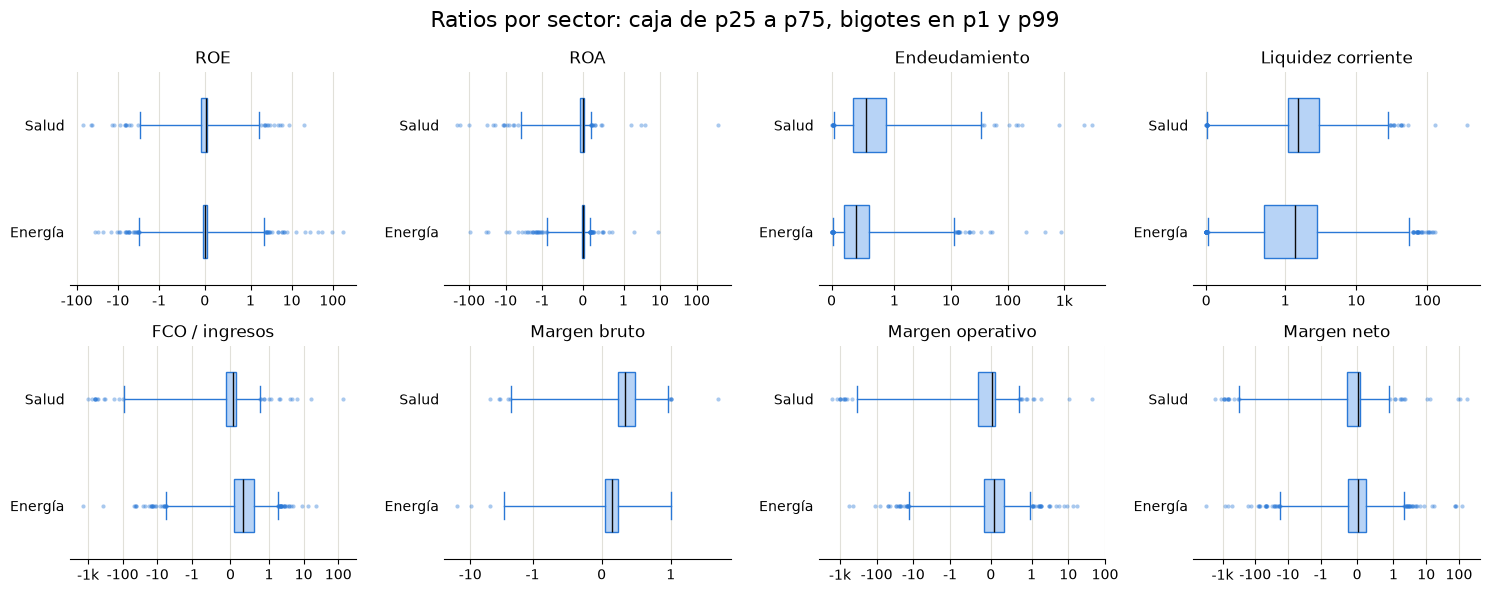

In [71]:
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, ratio in zip(axes.flat, RATIOS):
    ax.boxplot(
        [panel_qc.loc[panel_qc["sector"] == s, ratio].dropna() for s in NOMBRES],
        orientation="horizontal",
        tick_labels=list(NOMBRES.values()),
        whis=(1, 99),  # whiskers at p1 and p99: the points are the outliers
        widths=0.5,
        patch_artist=True,
        boxprops={"facecolor": "#b7d3f6", "edgecolor": AZUL},
        whiskerprops={"color": AZUL},
        capprops={"color": AZUL},
        medianprops={"color": "#0b0b0b"},
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": AZUL,
            "markeredgecolor": "none",
            "alpha": 0.4,
        },
    )
    ax.set_xscale("symlog", linthresh=1)
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda v, _: f"{v / 1000:g}k" if abs(v) >= 1000 else f"{v:g}")
    )
    ax.set_title(ETIQUETAS[ratio])
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="#e1e0d9")
    ax.set_axisbelow(True)
fig.suptitle("Ratios por sector: caja de p25 a p75, bigotes en p1 y p99", fontsize=16)
fig.tight_layout()

### ¿A qué se deben?

Un ratio es una división: explota cuando el denominador es chico o tiene un signo que no corresponde. Para cada valor fuera del umbral se mira su denominador:

- `denominador ≤ 0`: patrimonio negativo, ingresos negativos o nulos.
- `denominador chico`: el denominador está en el 5% más chico (en valor absoluto) de ese ratio.
- `resto`: valores extremos con un denominador normal.

`de quiebras` es el porcentaje que viene de empresas que quiebran, que son el 11,5% de las filas de `panel_qc`.

In [72]:
causas = []
for ratio, denominador in DENOMINADOR.items():
    datos = panel_qc[["sector", "fecha_quiebra", ratio, denominador]].dropna(
        subset=[ratio]
    )
    limites = datos.groupby("sector")[ratio].quantile([0.01, 0.99]).unstack()
    fuera = datos[
        (datos[ratio] < datos["sector"].map(limites[0.01]))
        | (datos[ratio] > datos["sector"].map(limites[0.99]))
    ]
    chico = datos[denominador].abs().quantile(0.05)
    causa = pd.Series(
        np.select(
            [fuera[denominador] <= 0, fuera[denominador].abs() <= chico],
            ["denominador ≤ 0", "denominador chico"],
            "resto",
        )
    )
    causas.append(
        {
            "ratio": ratio,
            "con dato": len(datos),
            "fuera": len(fuera),
            **causa.value_counts().reindex(
                ["denominador ≤ 0", "denominador chico", "resto"], fill_value=0
            ),
            "de quiebras": fuera["fecha_quiebra"].notna().mean().round(2),
        }
    )
pd.DataFrame(causas).set_index("ratio")

,con dato,fuera,denominador ≤ 0,denominador chico,resto,de quiebras
ratio,,,,,,
roe,3701,76,28,17,31,0.30
roa,3943,82,0,34,48,0.10
endeudamiento,3166,64,0,32,32,0.02
liquidez_corriente,4010,82,0,31,51,0.05
fco_ingresos,3807,78,7,43,28,0.13
margen_bruto,697,13,1,4,8,0.54
margen_operativo,3284,68,9,28,31,0.15
margen_neto,3771,78,10,43,25,0.14


Los casos más extremos de cada ratio, con su numerador y su denominador:

In [73]:
extremos = []
for ratio, denominador in DENOMINADOR.items():
    filas = panel_qc.loc[panel_qc[ratio].abs().nlargest(3).index]
    extremos.append(
        filas[["nombre", "sector", "trimestre", ratio, denominador]]
        .rename(columns={ratio: "valor", denominador: "denominador"})
        .assign(ratio=ratio)
    )
pd.concat(extremos).set_index(["ratio", "nombre"])

sector trimestre  \
ratio              nombre                                               
roe                PETROGAS CO                      energia    2021Q3   
                   GB SCIENCES INC                  energia    2020Q1   
                   BIOCORRX INC.                      salud    2019Q3   
roa                EDGEMODE, INC.                     salud    2024Q4   
                   EDGEMODE, INC.                     salud    2024Q3   
                   EDGEMODE, INC.                     salud    2024Q2   
endeudamiento      EDGEMODE, INC.                     salud    2024Q4   
                   EDGEMODE, INC.                     salud    2024Q2   
                   PETROGAS CO                      energia    2019Q1   
liquidez_corriente AGAPE ATP CORP                     salud    2018Q1   
                   AGAPE ATP CORP                     salud    2018Q2   
                   RESERVE PETROLEUM CO             energia    2019Q4   
fco_ingresos       TORCHLIGHT ENERGY RESOURCES INC  energia    2021Q1   
                   VIRIDIAN THERAPEUTICS, INC.DE      salud    2024Q4   
                   VIRIDIAN THERAPEUTICS, INC.DE      salud    2024Q3   
margen_bruto       DAWSON GEOPHYSICAL CO            energia    2021Q2   
                   TORCHLIGHT ENERGY RESOURCES INC  energia    2020Q4   
                   BIOCEPT INC                        salud    2022Q4   
margen_operativo   VIRIDIAN THERAPEUTICS, INC.DE      salud    2020Q4   
                   VIRIDIAN THERAPEUTICS, INC.DE      salud    2024Q4   
                   VIRIDIAN THERAPEUTICS, INC.DE      salud    2024Q2   
margen_neto        TORCHLIGHT ENERGY RESOURCES INC  energia    2020Q4   
                   VIRIDIAN THERAPEUTICS, INC.DE      salud    2020Q4   
                   VIRIDIAN THERAPEUTICS, INC.DE      salud    2024Q4   

                                                          valor  denominador  
ratio              nombre                                                     
roe                PETROGAS CO                       180.292280    -582524.0  
                   GB SCIENCES INC                    97.502034     -88494.0  
                   BIOCORRX INC.                     -71.893672      14380.0  
roa                EDGEMODE, INC.                    382.498337       1503.0  
                   EDGEMODE, INC.                   -213.053786       6563.0  
                   EDGEMODE, INC.                   -177.634009       1776.0  
endeudamiento      EDGEMODE, INC.                   3143.391883       1503.0  
                   EDGEMODE, INC.                   2196.742117       1776.0  
                   PETROGAS CO                       889.958656        387.0  
liquidez_corriente AGAPE ATP CORP                    359.403049      11609.0  
                   AGAPE ATP CORP                    127.603227      29750.0  
                   RESERVE PETROLEUM CO              125.705062     182011.0  
fco_ingresos       TORCHLIGHT ENERGY RESOURCES INC -1431.288142       2471.0  
                   VIRIDIAN THERAPEUTICS, INC.DE   -1018.500000      72000.0  
                   VIRIDIAN THERAPEUTICS, INC.DE    -787.279070      86000.0  
margen_bruto       DAWSON GEOPHYSICAL CO             -16.253886     193000.0  
                   TORCHLIGHT ENERGY RESOURCES INC    -9.780128       1560.0  
                   BIOCEPT INC                         5.718510    -913000.0  
margen_operativo   VIRIDIAN THERAPEUTICS, INC.DE   -1677.740741      54000.0  
                   VIRIDIAN THERAPEUTICS, INC.DE   -1214.888889      72000.0  
                   VIRIDIAN THERAPEUTICS, INC.DE   -1002.597222      72000.0  
margen_neto        TORCHLIGHT ENERGY RESOURCES INC -3143.482051       1560.0  
                   VIRIDIAN THERAPEUTICS, INC.DE   -1680.407407      54000.0  
                   VIRIDIAN THERAPEUTICS, INC.DE   -1107.291667      72000.0

### ROE con patrimonio negativo

El ROE con patrimonio negativo no queda fuera del umbral, pero no tiene sentido: una pérdida dividida por un patrimonio negativo da un ROE positivo, y una ganancia da uno negativo (por ejemplo, HCA).

In [74]:
negativo = panel_qc[panel_qc["patrimonio_neto"] <= 0]
pd.DataFrame(
    {
        "% de filas": negativo.groupby("sector").size()
        / panel_qc.groupby("sector").size(),
        "empresas": negativo.groupby("sector")["cik"].nunique(),
    }
).round(3)

,% de filas,empresas
sector,,
energia,0.114,39
salud,0.182,18


### Conclusión

Los valores anómalos tienen cuatro causas:

1. **Denominador casi nulo.** Empresas cáscara, casi sin activos (Edgemode con 1.503 dólares de activos, Petrogas con 387), y empresas que todavía casi no venden (Viridian Therapeutics: 72.000 dólares de ingresos y 70 millones de pérdida por trimestre).
2. **Denominador negativo.** Patrimonio negativo en el ROE (11% de las filas de energía y 18% de las de salud) e ingresos negativos por devoluciones (Biocept).
3. **Valores reales.** Empresas con muy poca deuda (Dorchester Minerals y CKX Lands, endeudamiento de 0,01), con mucha caja frente a sus deudas de corto plazo (Reserve Petroleum, liquidez de más de 100) o con pérdidas por deterioro de activos antes de quebrar (Jones Energy, ROA de −2,94).
4. **Errores de carga.** Petrogas 2021Q3 tiene un resultado neto de −105 millones; sus otros trimestres rondan los −20.000 (probable error de escala).

Propuesta de tratamiento (para la fase 3):

- ROE vacío cuando el patrimonio es ≤ 0; márgenes y FCO / ingresos vacíos cuando los ingresos son ≤ 0.
- Winsorizar: recortar cada ratio al p1 y al p99 de su sector, sin borrar filas. Los extremos de las empresas que quiebran son señal (30% de los ROE fuera del umbral), y recortarlos los deja como los valores más extremos sin que deformen las medias.